In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset_path = r"C:\Users\user\Documents\E-Commerce-Customer-Business-Analytics\data\processed"

customers = pd.read_csv(dataset_path + r"\customers_cleaned.csv")
orders = pd.read_csv(dataset_path + r"\orders_cleaned.csv")

orders["order_date"] = pd.to_datetime(orders["order_date"])

print("RFM Analysis Environment Ready!")
print("Customers:", len(customers))
print("Orders:", len(orders))

RFM Analysis Environment Ready!
Customers: 25000
Orders: 100000


In [3]:
reference_date = orders["order_date"].max() + pd.Timedelta(days=1)

rfm = orders.groupby("customer_id").agg(
    Recency=("order_date", lambda x: (reference_date - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("final_amount", "sum")
).reset_index()

print(rfm.head())
print("\nTotal Customers in RFM:", len(rfm))

  customer_id  Recency  Frequency   Monetary
0  CUST100000      951          3   36884.57
1  CUST100001      588          7  371585.73
2  CUST100002      171         10  114901.74
3  CUST100003       13          1    3788.82
4  CUST100004      792          2   61295.90

Total Customers in RFM: 22820


In [4]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first", ascending=False),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

print(rfm.head(10))

  customer_id  Recency  Frequency   Monetary  R_Score  F_Score  M_Score  \
0  CUST100000      951          3   36884.57        1        2        2   
1  CUST100001      588          7  371585.73        2        4        5   
2  CUST100002      171         10  114901.74        3        5        4   
3  CUST100003       13          1    3788.82        5        1        1   
4  CUST100004      792          2   61295.90        1        1        3   
5  CUST100005      858          4  250948.22        1        3        5   
6  CUST100006      775          3   78978.17        1        2        3   
7  CUST100008        8          5   27952.16        5        4        2   
8  CUST100009      571          3  110734.83        2        2        4   
9  CUST100012       72          3   10843.03        4        2        1   

  RFM_Score  
0       122  
1       245  
2       354  
3       511  
4       113  
5       135  
6       123  
7       542  
8       224  
9       421  


In [5]:
conditions = [
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 4),
    (rfm["F_Score"] >= 4),
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 2),
    (rfm["R_Score"] <= 2) & (rfm["F_Score"] >= 3),
    (rfm["R_Score"] <= 2) & (rfm["F_Score"] <= 2)
]

segments = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "At Risk",
    "Lost Customers"
]

rfm["Customer_Segment"] = np.select(
    conditions, segments, default="Regular Customers"
)

print(rfm["Customer_Segment"].value_counts())

Customer_Segment
Loyal Customers        6010
Regular Customers      4186
Lost Customers         4171
Potential Loyalists    3556
Champions              3118
At Risk                1779
Name: count, dtype: int64


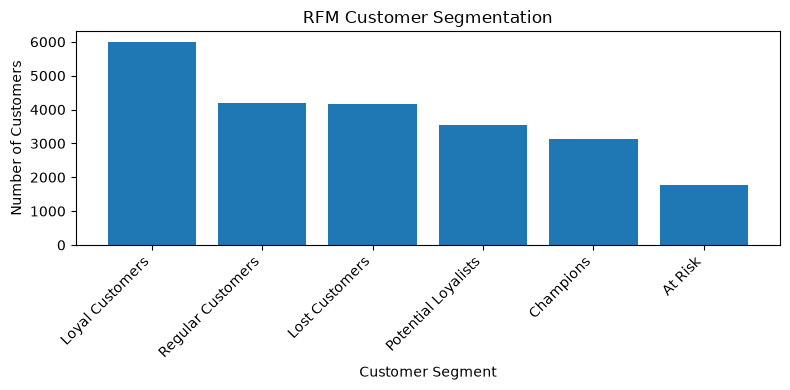

In [10]:
segment_counts = rfm["Customer_Segment"].value_counts()

plt.figure(figsize=(8, 4))
plt.bar(segment_counts.index, segment_counts.values)

plt.title("RFM Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [6]:
purchase_frequency = orders.groupby("customer_id")["order_id"].nunique()

repeat_customers = (purchase_frequency > 1).sum()
one_time_customers = (purchase_frequency == 1).sum()

print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Purchase Rate:", round(repeat_customers / len(purchase_frequency) * 100, 2), "%")

Repeat Customers: 18912
One-Time Customers: 3908
Repeat Purchase Rate: 82.87 %


In [7]:
clv = rfm[["customer_id", "Frequency", "Monetary"]].copy()

clv = clv.sort_values("Monetary", ascending=False)

print("TOP 10 CUSTOMERS BY HISTORICAL CLV:")
print(clv.head(10))

TOP 10 CUSTOMERS BY HISTORICAL CLV:
      customer_id  Frequency    Monetary
15851  CUST117355         16  1400278.07
16045  CUST117572         17  1160102.38
21982  CUST124072         12  1157867.11
8107   CUST108876         10  1099960.27
10965  CUST112006         13  1094821.46
2497   CUST102738         15  1092864.90
17507  CUST119192         13  1091212.75
19197  CUST121038         18  1040198.22
21251  CUST123291         20  1032582.00
16938  CUST118572         16  1022477.97


In [8]:
segment_summary = rfm.groupby("Customer_Segment").agg(
    Total_Customers=("customer_id", "count"),
    Average_Frequency=("Frequency", "mean"),
    Average_Spending=("Monetary", "mean")
).round(2).sort_values("Total_Customers", ascending=False)

print(segment_summary)

                     Total_Customers  Average_Frequency  Average_Spending
Customer_Segment                                                         
Loyal Customers                 6010               7.11         172248.25
Regular Customers               4186               1.89          44420.75
Lost Customers                  4171               1.63          36809.07
Potential Loyalists             3556               2.89          67860.08
Champions                       3118               8.41         259466.03
At Risk                         1779               3.39          82956.11


In [9]:
rfm.to_csv(
    dataset_path + r"\rfm_customer_analysis.csv",
    index=False
)

print("RFM Analysis Saved Successfully!")

RFM Analysis Saved Successfully!
